# 04 - Attribute router on SDXL (free-Colab version)

Team One Sheep Army | Standalone notebook: reloads everything, runs on a free T4. Run **01b first** (it writes `metadata_with_conflicts.jsonl`).

## What this notebook does (maps to the deliverables)

| Deliverable | Where |
|---|---|
| 1. Multimodal conditioning | sketch polarity fix + letterbox -> scribble ControlNet; caption -> SDXL text encoders; reference -> IP-Adapter encoder; plus CLIP conflict features (cells 3-6) |
| 2. Constraint-aware diffusion | custom denoising loop with per-step modality weights and constraint guidance (cell 7) |
| 3. Modality-specific control | **router MLP with 4 attribute-tied outputs**: sketch strength + sketch hold time (geometry / layout), reference strength (appearance), text guidance strength (semantics) (cell 10) |
| 4. Conflict resolution | labeled conflicts (01b) + schedule + guidance whose loss weights follow the router (cells 7, 11) |
| 5. Evaluation | held-out metrics, per conflict kind, paired confidence intervals (cells 12-14) |

## The four arms
`fixed` (constant weights) -> `scheduled` (geometry first, appearance later) -> `router` (learned per-item weights) -> `router_guided` (router + constraint guidance).

## How the router is trained (and why it is honest)
1. **Grid (Stage A)**: for each train item, 9 images: a centre point plus each of 4 factors moved to its low and high level (one-factor-at-a-time).
2. **Targets**: per factor, a soft-best level from a composite of geometry, appearance and semantics scores (main-effects assumption).
3. **Router**: 6 conflict features -> 4 outputs. Checked with **5-fold cross-validation against a constant predictor and a per-kind oracle**. If it does not beat them, the report must say so.
4. **Evaluation (Stage B)** uses *different* metrics from the ones used for targets and guidance (CLIP-B/32, Canny edges, colour histogram, DINO, LPIPS), so the arms are not graded on what they were optimised for.

## Free-Colab notes
- `PROFILE = "fast"` is about 1 hour on a T4 (162 grid + about 70 eval images). `"full"` reuses the fast images and adds items and a second seed (about 2 hours total).
- Everything is saved to Drive and resumable. After a disconnect: rerun cells 1 to 7, then continue from where you stopped.
- Do not run other GPU notebooks at the same time.

In [ ]:
# ---- CONFIG ----
PROFILE = "fast"          # "fast" (~1 h) or "full" (~2 h). Same images are reused when you switch.
PROFILES = {
    "fast": dict(N_TRAIN=dict(normal=6,  sem=4, color=2, material=2, app=4), N_EVAL=dict(normal=8,  sem=4, color=2, material=2, app=4), EVAL_SEEDS=[0]),
    "full": dict(N_TRAIN=dict(normal=10, sem=6, color=3, material=3, app=6), N_EVAL=dict(normal=12, sem=6, color=3, material=3, app=6), EVAL_SEEDS=[0, 1]),
}
DRIVE_ROOT = "/content/drive/MyDrive/sketchy_dataset_one_sketch"
ZIP_PATH = f"{DRIVE_ROOT}/pilot_v1.zip"
LOCAL_DATA = "/content/pilot_v1"
CONFLICT_FILE = f"{DRIVE_ROOT}/metadata_with_conflicts.jsonl"
RUN = "router_v2"
OUT = f"{DRIVE_ROOT}/sdxl_runs/{RUN}"

RES, STEPS = 640, 20
NEG = "blurry, low quality, text, watermark, multiple objects, cropped"
KIND_OF = {"object_text_sketch": "sem", "color_text_ref": "color", "material_text_ref": "material", "appearance_ref_swap": "app"}
GROUP = dict(normal="normal", sem="object_conflict", color="attribute_conflict", material="attribute_conflict", app="ref_swap_conflict")

# the four routed factors, each tied to one attribute / modality
#   cs   : sketch strength            -> geometry (sketch)
#   hold : fraction of steps the sketch stays strong -> shape / layout persistence (sketch)
#   ip   : reference strength         -> appearance (reference)
#   cfg  : text guidance strength     -> semantics (text)
LEVELS = dict(cs=[0.5, 1.0, 1.4], hold=[0.4, 0.7, 1.0], ip=[0.2, 0.5, 0.8], cfg=[4.0, 7.0, 10.0])
CENTER = dict(cs=1.0, hold=0.7, ip=0.5, cfg=7.0)
FACTORS = list(LEVELS)
RANGES = {k: (min(v), max(v)) for k, v in LEVELS.items()}
RELAX = 0.3                                    # sketch strength multiplier after the hold time
W = dict(geo=1.0, app=1.0, sem=1.0)           # composite utility weights used for the grid targets
SOFT_TEMP = 0.5

GUIDE_W, GUIDE_START, GUIDE_END, GUIDE_EVERY = 0.25, 0.25, 0.75, 2
LAMBDA_GEO, LAMBDA_APP = 1.0, 1.0

BASE_ID = "stabilityai/stable-diffusion-xl-base-1.0"
VAE_ID = "madebyollin/sdxl-vae-fp16-fix"
CN_ID = "xinsir/controlnet-scribble-sdxl-1.0"
IP_REPO, IP_SUBFOLDER, IP_WEIGHT, ENC_SUBFOLDER = "h94/IP-Adapter", "sdxl_models", "ip-adapter_sdxl_vit-h.safetensors", "models/image_encoder"
CLIP_ID, DINO_ID = "openai/clip-vit-large-patch14", "facebook/dinov2-small"      # used for targets + guidance
CLIPB_ID = "openai/clip-vit-base-patch32"                                       # held-out evaluation only

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
from google.colab import drive
drive.mount("/content/drive")
N_TRAIN, N_EVAL, EVAL_SEEDS = PROFILES[PROFILE]["N_TRAIN"], PROFILES[PROFILE]["N_EVAL"], PROFILES[PROFILE]["EVAL_SEEDS"]
os.makedirs(OUT, exist_ok=True)
print("profile:", PROFILE, "| train", N_TRAIN, "| eval", N_EVAL, "| seeds", EVAL_SEEDS)

Mounted at /content/drive
profile: fast | train {'normal': 6, 'sem': 4, 'color': 2, 'material': 2, 'app': 4} | eval {'normal': 8, 'sem': 4, 'color': 2, 'material': 2, 'app': 4} | seeds [0]


In [ ]:
!pip install -q -U diffusers transformers accelerate safetensors lpips
import torch, json, glob, zipfile, hashlib, time, gc, psutil, random
import numpy as np, pandas as pd
import torch.nn.functional as F
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
print("GPU:", torch.cuda.get_device_name(0), "|", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")

GPU: Tesla T4 | 15.6 GB


In [ ]:
# ---- data + items ----
if not glob.glob(f"{LOCAL_DATA}/**/metadata.jsonl", recursive=True):
    os.makedirs(LOCAL_DATA, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(LOCAL_DATA)
meta_path = glob.glob(f"{LOCAL_DATA}/**/metadata.jsonl", recursive=True)[0]
DATA_DIR = os.path.dirname(meta_path)

def resolve(p):
    full = os.path.join(DATA_DIR, p)
    assert os.path.exists(full), full
    return full

def letterbox(im, size, fill):
    im = ImageOps.contain(im, (size, size), Image.LANCZOS)
    c = Image.new("RGB", (size, size), fill)
    c.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    return c

def prep_sketch(path):      # white lines on black (what the scribble ControlNet expects)
    im = Image.open(path).convert("L")
    if np.array(im).mean() > 127:
        im = ImageOps.invert(im)
    return letterbox(im.convert("RGB"), RES, (0, 0, 0))

def prep_ref(path):
    return letterbox(Image.open(path).convert("RGB"), RES, (127, 127, 127))

def attr_phrase(r):
    return f"a {r['ref_finish']} {r['ref_material']} object in {r['ref_colors']} colors"

def seed_for(s):
    return int(hashlib.md5(str(s).encode()).hexdigest()[:8], 16)

assert os.path.exists(CONFLICT_FILE), "metadata_with_conflicts.jsonl not found: run notebook 01b first."
rows_all = [json.loads(l) for l in open(CONFLICT_FILE) if l.strip()]

def row_item(r, kind):
    bid = r.get("original_id", r["id"])
    return dict(key=r["id"], kind=kind, group=GROUP[kind], base=bid, base_row=r, caption=r["caption"],
                cap_category=r.get("caption_category", r["category"]), sk_category=r["category"],
                ref=r["reference"], attr=attr_phrase(r), seed=seed_for(bid))

def make_items(split, n):
    pool = [r for r in rows_all if r["split"] == split]
    items = []
    for kind, k in n.items():
        sel = [r for r in pool if (r["conflict_type"] == "none" if kind == "normal" else KIND_OF.get(r["conflict_type"]) == kind)][:k]
        items += [row_item(r, kind) for r in sel]
    return items

train_items, eval_items = make_items("train", N_TRAIN), make_items("test", N_EVAL)
assert not ({i["key"] for i in train_items} & {i["key"] for i in eval_items}), "train/test overlap"
KINDS = [k for k in ("normal", "sem", "color", "material", "app") if any(i["kind"] == k for i in eval_items)]
ALL_ITEMS = train_items + eval_items
print("train:", {k: sum(i["kind"] == k for i in train_items) for k in KINDS})
print("eval :", {k: sum(i["kind"] == k for i in eval_items) for k in KINDS})
for k in KINDS:
    it = next(i for i in train_items if i["kind"] == k)
    print(f"{k:9s}| caption: {it['caption'][:55]!r} | caption obj: {it['cap_category']} | sketch obj: {it['sk_category']} | ref attr: {it['attr']}")

train: {'normal': 6, 'sem': 4, 'color': 2, 'material': 2, 'app': 4}
eval : {'normal': 8, 'sem': 4, 'color': 2, 'material': 2, 'app': 4}
normal   | caption: 'Blue-handled hammer with wooden handle.' | caption obj: hammer | sketch obj: hammer | ref attr: a glossy plastic object in blue and white colors
sem      | caption: 'A person holds a shiny, silver French horn.' | caption obj: trumpet | sketch obj: hammer | ref attr: a glossy plastic object in blue and white colors
color    | caption: 'Pink-handled hammer with wooden handle.' | caption obj: hammer | sketch obj: hammer | ref attr: a glossy plastic object in blue and white colors
material | caption: 'Blue-handled hammer with stone handle.' | caption obj: hammer | sketch obj: hammer | ref attr: a glossy plastic object in blue and white colors
app      | caption: 'Blue-handled hammer with wooden handle.' | caption obj: hammer | sketch obj: hammer | ref attr: a matte solid object in grey colors


In [ ]:
# ---- load models (each straight onto the GPU so system RAM stays low) ----
dt = torch.float16
from diffusers import (UNet2DConditionModel, ControlNetModel, AutoencoderKL,
                       StableDiffusionXLControlNetPipeline, EulerDiscreteScheduler)
from transformers import (CLIPTextModel, CLIPTextModelWithProjection, CLIPTokenizer,
                          CLIPVisionModelWithProjection, AutoModel)
def ram(): return round(psutil.virtual_memory().used / 1e9, 1)
def gpu(): return round(torch.cuda.memory_allocated() / 1e9, 2)
def to_gpu(m, name):
    m = m.to("cuda"); gc.collect()
    print(f"{name:10s} | RAM {ram()} GB | GPU {gpu()} GB")
    return m

vae = to_gpu(AutoencoderKL.from_pretrained(VAE_ID, torch_dtype=dt), "vae")
unet = to_gpu(UNet2DConditionModel.from_pretrained(BASE_ID, subfolder="unet", torch_dtype=dt, variant="fp16"), "unet")
controlnet = to_gpu(ControlNetModel.from_pretrained(CN_ID, torch_dtype=dt), "controlnet")
te1 = to_gpu(CLIPTextModel.from_pretrained(BASE_ID, subfolder="text_encoder", torch_dtype=dt, variant="fp16"), "text enc 1")
te2 = to_gpu(CLIPTextModelWithProjection.from_pretrained(BASE_ID, subfolder="text_encoder_2", torch_dtype=dt, variant="fp16"), "text enc 2")
enc = to_gpu(CLIPVisionModelWithProjection.from_pretrained(IP_REPO, subfolder=ENC_SUBFOLDER, torch_dtype=dt), "ip enc")
tok1 = CLIPTokenizer.from_pretrained(BASE_ID, subfolder="tokenizer")
tok2 = CLIPTokenizer.from_pretrained(BASE_ID, subfolder="tokenizer_2")
sched = EulerDiscreteScheduler.from_pretrained(BASE_ID, subfolder="scheduler")
pipe = StableDiffusionXLControlNetPipeline(vae=vae, text_encoder=te1, text_encoder_2=te2, tokenizer=tok1, tokenizer_2=tok2,
                                           unet=unet, controlnet=controlnet, scheduler=sched, image_encoder=enc)
pipe.load_ip_adapter(IP_REPO, subfolder=IP_SUBFOLDER, weight_name=IP_WEIGHT)
pipe.set_progress_bar_config(disable=True)

CLIPV = to_gpu(CLIPVisionModelWithProjection.from_pretrained(CLIP_ID, torch_dtype=dt), "clip vis")
CLIPT = to_gpu(CLIPTextModelWithProjection.from_pretrained(CLIP_ID, torch_dtype=dt), "clip txt")
CLIPTOK = CLIPTokenizer.from_pretrained(CLIP_ID)
DINO = to_gpu(AutoModel.from_pretrained(DINO_ID, torch_dtype=dt), "dino")
for m in (vae, unet, controlnet, CLIPV, CLIPT, DINO):
    m.requires_grad_(False); m.eval()
print("all models ready | GPU", gpu(), "GB | RAM", ram(), "GB")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

vae        | RAM 3.8 GB | GPU 0.17 GB


...

tokenizer_config.json:   0%|          | 0.00/725 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/460 [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/479 [00:00<?, ?B/s]

sdxl_models/ip-adapter_sdxl_vit-h.safete(…): reconstructing file:   0%|          |  0.00B /  698MB            

sdxl_models/ip-adapter_sdxl_vit-h.safete(…): downloading bytes:           |  0.00B            

In [ ]:
# ---- helpers (optimisation-side metrics: CLIP-L + Sobel edges; evaluation uses different ones later) ----
dev = "cuda"
MEAN_C = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=dev).view(1, 3, 1, 1)
STD_C = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=dev).view(1, 3, 1, 1)
MEAN_I = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD_I = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def to_t(pil, size=None):
    if size: pil = pil.resize((size, size), Image.BICUBIC)
    return torch.from_numpy(np.array(pil.convert("RGB"))).permute(2, 0, 1)[None].float().to(dev) / 255

def clip_img(x):
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
    return F.normalize(CLIPV(pixel_values=((x - MEAN_C) / STD_C).to(dt)).image_embeds.float(), dim=-1)

@torch.no_grad()
def clip_txt(strs):
    tk = CLIPTOK(strs, padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(dev)
    return F.normalize(CLIPT(input_ids=tk.input_ids, attention_mask=tk.attention_mask).text_embeds.float(), dim=-1)

@torch.no_grad()
def dino_img(x):
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
    return F.normalize(DINO(pixel_values=((x - MEAN_I) / STD_I).to(dt)).last_hidden_state[:, 0].float(), dim=-1)

def edge_map(x):
    g = x.mean(1, keepdim=True)
    kx = torch.tensor([[-1., 0, 1], [-2, 0, 2], [-1, 0, 1]], device=x.device).view(1, 1, 3, 3)
    gx, gy = F.conv2d(g, kx, padding=1), F.conv2d(g, kx.transpose(2, 3), padding=1)
    return (gx ** 2 + gy ** 2 + 1e-6).sqrt()

def soft_sketch(sk_pil, size):
    t = torch.from_numpy(np.array(sk_pil.convert("L"))).float()[None, None].to(dev) / 255
    t = F.interpolate(t, size=(size, size), mode="area")
    t = (t > 0.35 * t.max()).float()
    return F.max_pool2d(t, 9, 1, 4)

def thin_np(sk_pil, size):         # undilated sketch mask as numpy bool (for the held-out edge metrics)
    t = torch.from_numpy(np.array(sk_pil.convert("L"))).float()[None, None] / 255
    t = F.interpolate(t, size=(size, size), mode="area")[0, 0].numpy()
    return t > 0.35 * t.max()

def geo_stats(x, S):
    E = edge_map(x); E = E / (E.amax() + 1e-6)
    return (E * S).sum() / (S.sum() + 1e-6), (E * (1 - S)).mean()

GL = RES // 16; GH = GL * 8
BASE = {}
with torch.no_grad():
    for it in tqdm(ALL_ITEMS, desc="base caches"):
        bid = it["base"]
        if bid in BASE: continue
        r = it["base_row"]
        sk = prep_sketch(resolve(r["sketch"]))
        sk_orig = letterbox(ImageOps.invert(sk.convert("L")).convert("RGB"), 224, (255, 255, 255))
        tgt = to_t(Image.open(resolve(r["target"])).convert("RGB"))
        BASE[bid] = dict(sketch=sk, sk_emb=clip_img(to_t(sk_orig)), S_gh=soft_sketch(sk, GH), S_256=soft_sketch(sk, 256),
                         thin256=thin_np(sk, 256), t_clip=clip_img(tgt), t_dino=dino_img(tgt))
print("base caches:", len(BASE))

In [ ]:
# ---- encode captions + references once, build the 6 conflict features, free the SDXL encoders ----
@torch.no_grad()
def encode_text(p):
    return [t.cpu() for t in pipe.encode_prompt(prompt=p, device=dev, num_images_per_prompt=1, do_classifier_free_guidance=True, negative_prompt=NEG)]

@torch.no_grad()
def encode_ip(img):
    return [t.cpu() for t in pipe.prepare_ip_adapter_image_embeds(ip_adapter_image=img, ip_adapter_image_embeds=None, device=dev,
                                                                   num_images_per_prompt=1, do_classifier_free_guidance=True)]

def conflict_features(it, sk_emb, ref_emb):
    cos = lambda a, b: float((a * b).sum())
    cat_emb = clip_txt([f"a photo of a {it['cap_category']}"])
    return [1 - cos(cat_emb, sk_emb),                  # object conflict: text vs sketch
            1 - cos(cat_emb, ref_emb),                 # object conflict: text vs reference
            1 - cos(it["cap_emb"], it["attr_emb"]),    # appearance conflict: text vs reference attributes
            1 - cos(sk_emb, ref_emb),                  # object conflict: sketch vs reference
            cos(it["cap_emb"], sk_emb), cos(it["cap_emb"], ref_emb)]

TXT, IPC, REFCLIP = {}, {}, {}
with torch.no_grad():
    for it in tqdm(ALL_ITEMS, desc="encode"):
        if it["caption"] not in TXT: TXT[it["caption"]] = encode_text(it["caption"])
        if it["ref"] not in IPC:
            ref = prep_ref(resolve(it["ref"]))
            IPC[it["ref"]] = encode_ip(ref)
            REFCLIP[it["ref"]] = clip_img(to_t(ref))
        it["cap_emb"], it["attr_emb"] = clip_txt([it["caption"]]), clip_txt([it["attr"]])
        it["obj_emb"] = clip_txt([f"a photo of a {it['cap_category']}"])       # semantics = object identity only
        it["feat"] = conflict_features(it, BASE[it["base"]]["sk_emb"], REFCLIP[it["ref"]])
pipe.text_encoder = None; pipe.text_encoder_2 = None; pipe.image_encoder = None
del te1, te2, enc
gc.collect(); torch.cuda.empty_cache()
pipe.vae.enable_slicing()
print("encoders freed | GPU", gpu(), "GB | RAM", ram(), "GB")

df = pd.DataFrame([dict(kind=i["kind"], **dict(zip(["obj_text_sketch", "obj_text_ref", "app_text_ref", "obj_sketch_ref", "cos_text_sketch", "cos_text_ref"], i["feat"]))) for i in ALL_ITEMS])
print("Do the conflict features separate the kinds?  (sem should be high in obj_text_sketch; color/material/app high in app_text_ref)")
print(df.groupby("kind").mean(numeric_only=True).round(3))

In [ ]:
# ---- denoising loop: per-step modality weights, per-item text strength, optional constraint guidance ----
def cs_shape(f, hold): return 1.0 if f < hold else RELAX
def ip_shape(f): return 0.0 if f < 0.15 else min(1.0, (f - 0.15) / 0.25)

def guidance_delta(x0, b, it, lam_geo, lam_app):
    x0g = x0.detach().float().requires_grad_(True)
    with torch.enable_grad():
        z = F.interpolate(x0g, size=(GL, GL), mode="area")
        img = vae.decode((z / vae.config.scaling_factor).to(dt), return_dict=False)[0]
        x = ((img.float() + 1) / 2).clamp(0, 1)
        rec, out = geo_stats(x, b["S_gh"])
        l_geo = (1 - rec) + 0.5 * out                                  # geometry: edges follow the sketch
        l_app = 1 - (clip_img(x) * it["attr_emb"]).sum()               # appearance: match reference attributes (not its object)
        g, = torch.autograd.grad(LAMBDA_GEO * lam_geo * l_geo + LAMBDA_APP * lam_app * l_app, x0g)
    return g / (g.abs().mean() + 1e-8)

@torch.no_grad()
def run_item(it, p, shaped=True, guided=False, seed_off=0):
    """p = dict(cs, hold, ip, cfg). shaped=False -> constant cs/ip over all steps (the 'fixed' arm)."""
    b = BASE[it["base"]]
    pe, npe, ppe, nppe = [t.to(dev) for t in TXT[it["caption"]]]
    pr, pooled = torch.cat([npe, pe]), torch.cat([nppe, ppe])
    tid = torch.tensor([[RES, RES, 0, 0, RES, RES]], device=dev, dtype=dt)
    tids = torch.cat([tid, tid])
    ipe = [e.to(dev) for e in IPC[it["ref"]]]
    ctrl = pipe.prepare_image(image=b["sketch"], width=RES, height=RES, batch_size=1, num_images_per_prompt=1,
                              device=dev, dtype=dt, do_classifier_free_guidance=True, guess_mode=False)
    pipe.scheduler.set_timesteps(STEPS, device=dev)
    ts = pipe.scheduler.timesteps
    g = torch.Generator("cpu").manual_seed(it["seed"] + seed_off)
    lat = torch.randn((1, 4, RES // 8, RES // 8), generator=g).to(dev, dt) * pipe.scheduler.init_noise_sigma
    lam_geo = float(np.clip(p["cs"] / CENTER["cs"], 0.3, 1.5))        # guidance weights follow the router's modality weights
    lam_app = float(np.clip(p["ip"] / CENTER["ip"], 0.3, 1.6))
    for i, t in enumerate(ts):
        f = i / len(ts)
        cs = p["cs"] * (cs_shape(f, p["hold"]) if shaped else 1.0)
        ips = p["ip"] * (ip_shape(f) if shaped else 1.0)
        li = pipe.scheduler.scale_model_input(torch.cat([lat] * 2), t)
        pipe.set_ip_adapter_scale(float(ips))
        kw = {}
        if cs > 1e-3:
            down, mid = pipe.controlnet(li, t, encoder_hidden_states=pr, controlnet_cond=ctrl, conditioning_scale=float(cs),
                                        guess_mode=False, added_cond_kwargs={"text_embeds": pooled, "time_ids": tids}, return_dict=False)
            kw = dict(down_block_additional_residuals=down, mid_block_additional_residual=mid)
        eps = pipe.unet(li, t, encoder_hidden_states=pr, added_cond_kwargs={"text_embeds": pooled, "time_ids": tids, "image_embeds": ipe},
                        return_dict=False, **kw)[0]
        eu, ec = eps.chunk(2)
        eps = eu + p["cfg"] * (ec - eu)                                 # text (semantics) strength is routed too
        if guided and GUIDE_START <= f <= GUIDE_END and i % GUIDE_EVERY == 0:
            x0 = lat - pipe.scheduler.sigmas[i].to(dev) * eps
            lat = lat - GUIDE_W * guidance_delta(x0, b, it, lam_geo, lam_app).to(dt)
        lat = pipe.scheduler.step(eps, t, lat, return_dict=False)[0]
    img = vae.decode(lat / vae.config.scaling_factor, return_dict=False)[0]
    return pipe.image_processor.postprocess(img, output_type="pil")[0]

@torch.no_grad()
def score_opt(img, it):
    """optimisation-side scores (used for grid targets). NOT used for the final claims."""
    b = BASE[it["base"]]
    cf = clip_img(to_t(img))
    rec, out = geo_stats(to_t(img, 256), b["S_256"])
    return dict(geo=float(rec) - 0.5 * float(out), app=float((cf * it["attr_emb"]).sum()), sem=float((cf * it["obj_emb"]).sum()))

SCORES_PATH = f"{OUT}/scores.json"
SCORES = json.load(open(SCORES_PATH)) if os.path.exists(SCORES_PATH) else {}
def save_scores(): json.dump(SCORES, open(SCORES_PATH, "w"))

def make_or_load(path, key, it, p, shaped, guided, seed_off=0, need_score=True):
    if os.path.exists(path):
        img = Image.open(path).convert("RGB")
    else:
        os.makedirs(os.path.dirname(path), exist_ok=True)
        img = run_item(it, p, shaped, guided, seed_off); img.save(path)
    if need_score and key not in SCORES:
        SCORES[key] = score_opt(img, it)
    return img

def grid_points():                    # centre + each factor moved to its other levels (one-factor-at-a-time)
    pts = [dict(CENTER)]
    for f in FACTORS:
        for v in LEVELS[f]:
            if v != CENTER[f]:
                q = dict(CENTER); q[f] = v; pts.append(q)
    return pts
def ptag(p): return "_".join(f"{k}{p[k]}" for k in FACTORS)
print("grid points per item:", len(grid_points()))

In [ ]:
# ---- sanity: one conflict item, three settings, timing and peak memory ----
torch.cuda.reset_peak_memory_stats()
it0 = next(i for i in eval_items if i["kind"] != "normal")
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
ax[0].imshow(BASE[it0["base"]]["sketch"]); ax[0].set_title("sketch"); ax[1].imshow(prep_ref(resolve(it0["ref"]))); ax[1].set_title("reference")
for a, (nm, kw) in zip(ax[2:], [("fixed", dict(shaped=False, guided=False)), ("scheduled", dict(shaped=True, guided=False)), ("scheduled+guided", dict(shaped=True, guided=True))]):
    t0 = time.time(); im = run_item(it0, CENTER, **kw); a.imshow(im); a.set_title(f"{nm} ({time.time() - t0:.0f}s)")
for a in ax: a.axis("off")
plt.show()
print("caption:", it0["caption"], "| peak GPU GB:", round(torch.cuda.max_memory_allocated() / 1e9, 2))
print("If sketch lines are ignored: raise LEVELS['cs']. If images are over-saturated or wavy with guidance: lower GUIDE_W.")

In [ ]:
# ---- Stage A: one-factor-at-a-time grid on the train items (resumable) ----
n_img = len(train_items) * len(grid_points())
print(f"{n_img} images to generate (existing ones are skipped)")
torch.cuda.reset_peak_memory_stats()
for it in tqdm(train_items, desc="grid"):
    for p in grid_points():
        make_or_load(f"{OUT}/grid/{ptag(p)}/{it['key']}.png", f"grid|{it['key']}|{ptag(p)}", it, p, True, False)
    save_scores(); torch.cuda.empty_cache()
print("grid done | peak GPU GB:", round(torch.cuda.max_memory_allocated() / 1e9, 2))

252 images to generate (existing ones are skipped)


grid:   0%|          | 0/28 [00:00<?, ?it/s]

grid done | peak GPU GB: 10.49


In [ ]:
# ---- targets + router (cross-validated against two baselines) ----
import torch.nn as nn
rows_ = []
for it in train_items:
    for p in grid_points():
        rows_.append(dict(item=it["key"], kind=it["kind"], **{f"p_{k}": p[k] for k in FACTORS}, **SCORES[f"grid|{it['key']}|{ptag(p)}"]))
G = pd.DataFrame(rows_)
for m in ("geo", "app", "sem"):
    G["z_" + m] = (G[m] - G[m].mean()) / (G[m].std() + 1e-8)
G["S"] = W["geo"] * G.z_geo + W["app"] * G.z_app + W["sem"] * G.z_sem

def norm(v, k): lo, hi = RANGES[k]; return (v - lo) / (hi - lo)
def denorm(u, k): lo, hi = RANGES[k]; return lo + float(u) * (hi - lo)

X, Y, KIND = [], [], []
for it in train_items:
    g = G[G.item == it["key"]]
    y = []
    for f in FACTORS:                         # main effect of factor f: the rows where all OTHER factors are at their centre
        mask = np.ones(len(g), bool)
        for o in FACTORS:
            if o != f: mask &= np.isclose(g[f"p_{o}"].values, CENTER[o])
        sel = g[mask]
        w = np.exp((sel.S - sel.S.max()) / SOFT_TEMP); w = w / w.sum()
        y.append(norm(float((w * sel[f"p_{f}"]).sum()), f))
    Y.append(y); X.append(it["feat"]); KIND.append(it["kind"])
X, Y = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
KIND = np.array(KIND)
print("target means per kind (0 = low level, 1 = high level):")
print(pd.DataFrame(Y.numpy(), columns=FACTORS).assign(kind=KIND).groupby("kind").mean().round(2))

class Router(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(6, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, len(FACTORS)), nn.Sigmoid())
    def forward(self, x): return self.net(x)

def fit(Xn, Yt, seed, epochs=500):
    torch.manual_seed(seed)
    m = Router(); opt = torch.optim.Adam(m.parameters(), lr=3e-3, weight_decay=1e-3)
    for _ in range(epochs):
        loss = F.mse_loss(m(Xn), Yt); opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

# 5-fold cross-validation vs (a) constant predictor, (b) per-kind-mean oracle (it is told the kind label)
K = min(5, len(X)); idx = list(range(len(X))); random.Random(0).shuffle(idx)
folds = [idx[k::K] for k in range(K)]
se_g, se_c, se_k = [], [], []
for k in range(K):
    va = folds[k]; tr = [i for i in idx if i not in va]
    mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-6
    m = fit((X[tr] - mu) / sd, Y[tr], seed=k)
    with torch.no_grad(): pg = m((X[va] - mu) / sd)
    pc = Y[tr].mean(0, keepdim=True).expand(len(va), -1)
    pk = torch.stack([Y[tr][torch.tensor(KIND[tr] == KIND[i])].mean(0) if (KIND[tr] == KIND[i]).any() else Y[tr].mean(0) for i in va])
    se_g.append(((pg - Y[va]) ** 2)); se_c.append(((pc - Y[va]) ** 2)); se_k.append(((pk - Y[va]) ** 2))
cv = pd.DataFrame({"router": torch.cat(se_g).mean(0).numpy(), "constant": torch.cat(se_c).mean(0).numpy(), "per-kind oracle": torch.cat(se_k).mean(0).numpy()}, index=FACTORS).round(4)
cv["router beats constant?"] = cv["router"] < cv["constant"]
print(f"\n{K}-fold cross-validated MSE per output (lower is better; n={len(X)} items):"); print(cv)
print("Honest reading: if 'router beats constant' is False for most outputs, report the router as not significantly better than a constant.")

MU, SD = X.mean(0), X.std(0) + 1e-6
ENS = [fit((X - MU) / SD, Y, seed=s) for s in range(5)]
def predict_params(it):
    with torch.no_grad():
        o = torch.stack([m((torch.tensor([it["feat"]], dtype=torch.float32) - MU) / SD)[0] for m in ENS]).mean(0)
    return {f: denorm(o[j], f) for j, f in enumerate(FACTORS)}
torch.save({"states": [m.state_dict() for m in ENS], "mu": MU, "sd": SD, "ranges": RANGES, "factors": FACTORS}, f"{OUT}/router.pt")
pa = pd.DataFrame([dict(kind=i["kind"], **predict_params(i)) for i in eval_items])
print("\nrouter outputs on the TEST items, by kind (this is the evidence for 'not equal weighting'):")
print(pa.groupby("kind").mean().round(2))

target means per kind (0 = low level, 1 = high level):
            cs  hold    ip   cfg
kind                            
app       0.50  0.46  0.56  0.59
color     0.38  0.45  0.43  0.63
material  0.38  0.35  0.57  0.73
normal    0.50  0.53  0.65  0.56
sem       0.51  0.53  0.78  0.49

5-fold cross-validated MSE per output (lower is better; n=28 items):
      router  constant  per-kind oracle  router beats constant?
cs    0.0832    0.1218           0.1689                    True
hold  0.0356    0.0371           0.0482                    True
ip    0.0886    0.0580           0.0668                   False
cfg   0.0809    0.0567           0.0751                   False
Honest reading: if 'router beats constant' is False for most outputs, report the router as not significantly better than a constant.

router outputs on the TEST items, by kind (this is the evidence for 'not equal weighting'):
            cs  hold    ip   cfg
kind                            
app       0.98  0.69  0.56  7.86

In [ ]:
# ---- Stage B: four arms on the test items ----
ARMS = {"fixed":         dict(src="center", shaped=False, guided=False),
        "scheduled":     dict(src="center", shaped=True,  guided=False),
        "router":        dict(src="router", shaped=True,  guided=False),
        "router_guided": dict(src="router", shaped=True,  guided=True)}
def params_for(it, arm): return dict(CENTER) if ARMS[arm]["src"] == "center" else predict_params(it)

torch.cuda.reset_peak_memory_stats()
manifest = []
for it in tqdm(eval_items, desc="eval"):
    for s in EVAL_SEEDS:
        for arm, a in ARMS.items():
            p = params_for(it, arm)
            path = f"{OUT}/eval/{arm}/{it['key']}_s{s}.png"
            make_or_load(path, "", it, p, a["shaped"], a["guided"], seed_off=s, need_score=False)
            manifest.append(dict(id=it["key"], kind=it["kind"], group=it["group"], mode=arm, seed=s, caption=it["caption"], category=it["sk_category"],
                                 target=it["base_row"]["target"], sketch=it["base_row"]["sketch"], reference=it["ref"], generated=path, **{f"p_{k}": v for k, v in p.items()}))
    torch.cuda.empty_cache()
with open(f"{OUT}/manifest_eval.jsonl", "w") as f:
    for m in manifest: f.write(json.dumps(m) + "\n")
print("eval images:", len(manifest), "| peak GPU GB:", round(torch.cuda.max_memory_allocated() / 1e9, 2))

eval:   0%|          | 0/30 [00:00<?, ?it/s]

eval images: 240 | peak GPU GB: 10.84


In [ ]:
# ---- held-out metrics (different models/operators from the ones used for targets and guidance) ----
import cv2, lpips
CBV = to_gpu(CLIPVisionModelWithProjection.from_pretrained(CLIPB_ID, torch_dtype=dt), "clipB vis").eval()
CBT = to_gpu(CLIPTextModelWithProjection.from_pretrained(CLIPB_ID, torch_dtype=dt), "clipB txt").eval()
CBTOK = CLIPTokenizer.from_pretrained(CLIPB_ID)
try:
    LP = lpips.LPIPS(net="alex", verbose=False).to(dev).eval()
except Exception as e:
    LP = None; print("LPIPS unavailable:", e)

@torch.no_grad()
def cb_img(x):
    x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
    return F.normalize(CBV(pixel_values=((x - MEAN_C) / STD_C).to(dt)).image_embeds.float(), dim=-1)
@torch.no_grad()
def cb_txt(strs):
    tk = CBTOK(strs, padding="max_length", max_length=77, truncation=True, return_tensors="pt").to(dev)
    return F.normalize(CBT(input_ids=tk.input_ids, attention_mask=tk.attention_mask).text_embeds.float(), dim=-1)

def color_hist(px, bins=6):
    q = np.clip(px // (256 // bins), 0, bins - 1).astype(int)
    h = np.bincount(q[:, 0] * bins * bins + q[:, 1] * bins + q[:, 2], minlength=bins ** 3).astype(float)
    return h / (np.linalg.norm(h) + 1e-9)

def ref_object_pixels(it):
    r = np.array(prep_ref(resolve(it["ref"])).resize((256, 256))).astype(float)
    border = np.concatenate([r[:6].reshape(-1, 3), r[-6:].reshape(-1, 3), r[:, :6].reshape(-1, 3), r[:, -6:].reshape(-1, 3)])
    m = np.linalg.norm(r - np.median(border, 0), axis=-1) > 30
    return r[m] if m.sum() > 200 else None

@torch.no_grad()
def heldout(img, it):
    b = BASE[it["base"]]
    out = {}
    # geometry (Canny, 256 px): does the output follow the sketch?
    g = np.array(img.resize((256, 256)).convert("L"))
    E = cv2.Canny(g, 80, 160) > 0
    thin = b["thin256"]; k = np.ones((7, 7), np.uint8)
    Ed, Td = cv2.dilate(E.astype(np.uint8), k) > 0, cv2.dilate(thin.astype(np.uint8), k) > 0
    out["edge_recall"] = float((thin & Ed).sum() / max(thin.sum(), 1))
    out["edge_precision"] = float((E & Td).sum() / max(E.sum(), 1))
    out["edge_iou"] = float((Ed & Td).sum() / max((Ed | Td).sum(), 1))
    # semantics (CLIP-B/32): does the object follow the caption / the sketch?
    ci = cb_img(to_t(img))
    out["sem_text"] = float((ci * cb_txt([f"a photo of a {it['cap_category']}"])).sum())
    out["sem_sketch"] = float((ci * cb_txt([f"a photo of a {it['sk_category']}"])).sum())
    out["sem_margin"] = out["sem_text"] - out["sem_sketch"]        # >0: reads as the caption's object, <0: as the sketch's
    # appearance: colour histogram of the reference object vs the generated region inside the sketch box; DINO to the reference; CLIP-B to the attribute phrase
    ys, xs = np.where(thin)
    out["color_match"] = np.nan
    ro = ref_object_pixels(it)
    if len(ys) and ro is not None:
        y0, y1, x0, x1 = max(ys.min() - 12, 0), min(ys.max() + 12, 255), max(xs.min() - 12, 0), min(xs.max() + 12, 255)
        gp = np.array(img.resize((256, 256)).convert("RGB"))[y0:y1, x0:x1].reshape(-1, 3)
        out["color_match"] = float((color_hist(gp) * color_hist(ro)).sum())
    out["dino_ref"] = float((dino_img(to_t(img)) * dino_img(to_t(prep_ref(resolve(it["ref"]))))).sum())
    out["attr_B"] = float((ci * cb_txt([it["attr"]])).sum())
    # fidelity to the ground-truth photo (only meaningful for aligned 'normal' items)
    if it["kind"] == "normal":
        tgt = letterbox(Image.open(resolve(it["base_row"]["target"])).convert("RGB"), 256, (127, 127, 127))
        out["dino_tgt"] = float((dino_img(to_t(img)) * b["t_dino"]).sum())
        out["clipI_tgt"] = float((clip_img(to_t(img)) * b["t_clip"]).sum())
        if LP is not None:
            a = to_t(img, 256) * 2 - 1; c = to_t(tgt) * 2 - 1
            out["lpips_tgt"] = float(LP(a, c))
    return out

HPATH = f"{OUT}/heldout.csv"
done = pd.read_csv(HPATH) if os.path.exists(HPATH) else pd.DataFrame()
have = set(zip(done.key, done.arm, done.seed)) if len(done) else set()
recs = done.to_dict("records") if len(done) else []
for it in tqdm(eval_items, desc="held-out metrics"):
    for s in EVAL_SEEDS:
        for arm in ARMS:
            if (it["key"], arm, s) in have: continue
            img = Image.open(f"{OUT}/eval/{arm}/{it['key']}_s{s}.png").convert("RGB")
            recs.append(dict(key=it["key"], kind=it["kind"], group=it["group"], arm=arm, seed=s, **heldout(img, it)))
H = pd.DataFrame(recs); H.to_csv(HPATH, index=False)
print("scored", len(H), "images")

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0

...

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth




  0%|          | 0.00/233M [00:00<?, ?B/s]

  3%|▎         | 5.88M/233M [00:00<00:04, 52.6MB/s]

  5%|▍         | 11.0M/233M [00:00<00:05, 44.9MB/s]

  8%|▊         | 18.2M/233M [00:00<00:04, 53.3MB/s]

 12%|█▏        | 27.2M/233M [00:00<00:03, 64.2MB/s]

 14%|█▍        | 33.5M/233M [00:00<00:04, 42.0MB/s]

 16%|█▋        | 38.4M/233M [00:01<00:06, 31.7MB/s]

 18%|█▊        | 42.2M/233M [00:01<00:07, 26.1MB/s]

 19%|█▉        | 45.4M/233M [00:01<00:08, 22.5MB/s]

 21%|██        | 48.0M/233M [00:01<00:10, 18.1MB/s]

 22%|██▏       | 50.1M/233M [00:05<01:14, 2.57MB/s]

 24%|██▍       | 55.4M/233M [00:05<00:45, 4.14MB/s]

 25%|██▍       | 57.9M/233M [00:06<00:36, 5.03MB/s]

 27%|██▋       | 62.6M/233M [00:06<00:23, 7.51MB/s]

 28%|██▊       | 65.8M/233M [00:06<00:18, 9.26MB/s]

 29%|██▉       | 68.8M/233M [00:06<00:15, 11.2MB/s]

 31%|███       | 71.8M/233M [00:06<00:12, 13.1MB/s]

 32%|███▏      | 74.5M/233M [00:06<00:11, 14.8MB/s]

 33%|███▎      | 77.1M/233M [00:06<00:11, 14.8MB/s]



held-out metrics:   0%|          | 0/30 [00:00<?, ?it/s]

scored 240 images


In [ ]:
# ---- results tables (mean over items; seeds averaged inside each item first; +- = standard error) ----
ORDER = list(ARMS)
Hi = H.groupby(["key", "kind", "group", "arm"], as_index=False).mean(numeric_only=True)
def table(cols, sub=None):
    d = Hi if sub is None else Hi[Hi.group.isin(sub)]
    m = d.groupby(["group", "arm"])[cols].mean(); s = d.groupby(["group", "arm"])[cols].sem()
    out = m.round(3).astype(str) + " +-" + s.round(3).astype(str)
    return out.reindex(pd.MultiIndex.from_product([sorted(d.group.unique()), ORDER]))
print("== GEOMETRY (sketch): edge recall / precision / IoU, higher is better ==");            print(table(["edge_recall", "edge_precision", "edge_iou"]))
print("\n== SEMANTICS (text): CLIP-B/32 similarity to the caption's object; sem_margin>0 = reads as caption object ==");   print(table(["sem_text", "sem_sketch", "sem_margin"]))
print("\n== APPEARANCE (reference): colour-histogram match, DINO to reference, CLIP-B to attribute phrase ==");           print(table(["color_match", "dino_ref", "attr_B"]))
print("\n== FIDELITY to the ground-truth photo (normal items only) ==");                         print(table([c for c in ["lpips_tgt", "dino_tgt", "clipI_tgt"] if c in Hi], sub=["normal"]))
Hi.to_csv(f"{OUT}/results_per_item.csv", index=False)

== GEOMETRY (sketch): edge recall / precision / IoU, higher is better ==
                                    edge_recall edge_precision       edge_iou
attribute_conflict fixed          0.995 +-0.002  0.667 +-0.111  0.619 +-0.116
                   scheduled       0.99 +-0.007   0.42 +-0.161  0.389 +-0.152
                   router         0.982 +-0.006  0.469 +-0.146  0.429 +-0.135
                   router_guided  0.986 +-0.005  0.381 +-0.133  0.348 +-0.125
normal             fixed          0.984 +-0.004   0.645 +-0.07  0.581 +-0.065
                   scheduled      0.972 +-0.008  0.415 +-0.068  0.361 +-0.058
                   router         0.973 +-0.006  0.383 +-0.059  0.338 +-0.051
                   router_guided  0.981 +-0.005  0.308 +-0.058   0.276 +-0.05
object_conflict    fixed          0.944 +-0.022  0.498 +-0.149  0.421 +-0.127
                   scheduled      0.971 +-0.008  0.209 +-0.077  0.205 +-0.073
                   router          0.967 +-0.02   0.242 +-0.08  0.224

In [ ]:
# ---- paired comparisons with bootstrap 95% CI (does each upgrade really help?) ----
METRICS = ["edge_recall", "edge_precision", "edge_iou", "sem_text", "sem_margin", "color_match", "dino_ref", "attr_B"]
rng = np.random.default_rng(0)
def paired(a, b, sub, label):
    out = []
    A = Hi[(Hi.arm == a) & Hi.group.isin(sub)].set_index("key"); B = Hi[(Hi.arm == b) & Hi.group.isin(sub)].set_index("key")
    ks = A.index.intersection(B.index)
    for m in METRICS:
        d = (A.loc[ks, m] - B.loc[ks, m]).dropna().values
        if len(d) < 3: continue
        bs = [rng.choice(d, len(d)).mean() for _ in range(2000)]
        lo, hi = np.percentile(bs, [2.5, 97.5])
        out.append(dict(comparison=f"{a} - {b}", items=label, metric=m, n=len(d), mean_diff=round(d.mean(), 4), ci_low=round(lo, 4), ci_high=round(hi, 4),
                        significant=("yes" if lo > 0 or hi < 0 else "no"), wins=f"{(d > 0).sum()}/{len(d)}"))
    return out
conf = ["object_conflict", "attribute_conflict", "ref_swap_conflict"]
P = []
for a, b in [("scheduled", "fixed"), ("router", "scheduled"), ("router_guided", "router"), ("router_guided", "fixed")]:
    P += paired(a, b, conf, "all conflict items") + paired(a, b, ["normal"], "normal items")
PT = pd.DataFrame(P); PT.to_csv(f"{OUT}/paired_comparisons.csv", index=False)
print(PT.to_string(index=False))
print("\nReading it: a metric improves only if ci_low > 0 (significant = yes). Report non-significant results as 'no clear difference'.")

# evidence for deliverable 3: do the router outputs differ across conflict kinds?
pa = pd.DataFrame([dict(kind=i["kind"], **predict_params(i)) for i in eval_items])
print("\nRouter outputs by conflict kind (test items):"); print(pa.groupby("kind").mean().round(2))
print("spread across kinds (max-min, as fraction of range):", {f: round((pa.groupby('kind')[f].mean().max() - pa.groupby('kind')[f].mean().min()) / (RANGES[f][1] - RANGES[f][0]), 2) for f in FACTORS})

            comparison              items         metric  n  mean_diff  ci_low  ci_high significant  wins
     scheduled - fixed all conflict items    edge_recall 18     0.0223  0.0012   0.0449         yes 10/18
     scheduled - fixed all conflict items edge_precision 18    -0.2885 -0.4030  -0.1775         yes  3/18
     scheduled - fixed all conflict items       edge_iou 18    -0.2425 -0.3369  -0.1534         yes  1/18
     scheduled - fixed all conflict items       sem_text 18     0.0052 -0.0047   0.0155          no 11/18
     scheduled - fixed all conflict items     sem_margin 18     0.0112 -0.0001   0.0262          no  4/18
     scheduled - fixed all conflict items    color_match 18    -0.0724 -0.1572  -0.0016         yes  5/18
     scheduled - fixed all conflict items       dino_ref 18    -0.0744 -0.1024  -0.0468         yes  1/18
     scheduled - fixed all conflict items         attr_B 18    -0.0238 -0.0375  -0.0121         yes  4/18
     scheduled - fixed       normal items    e

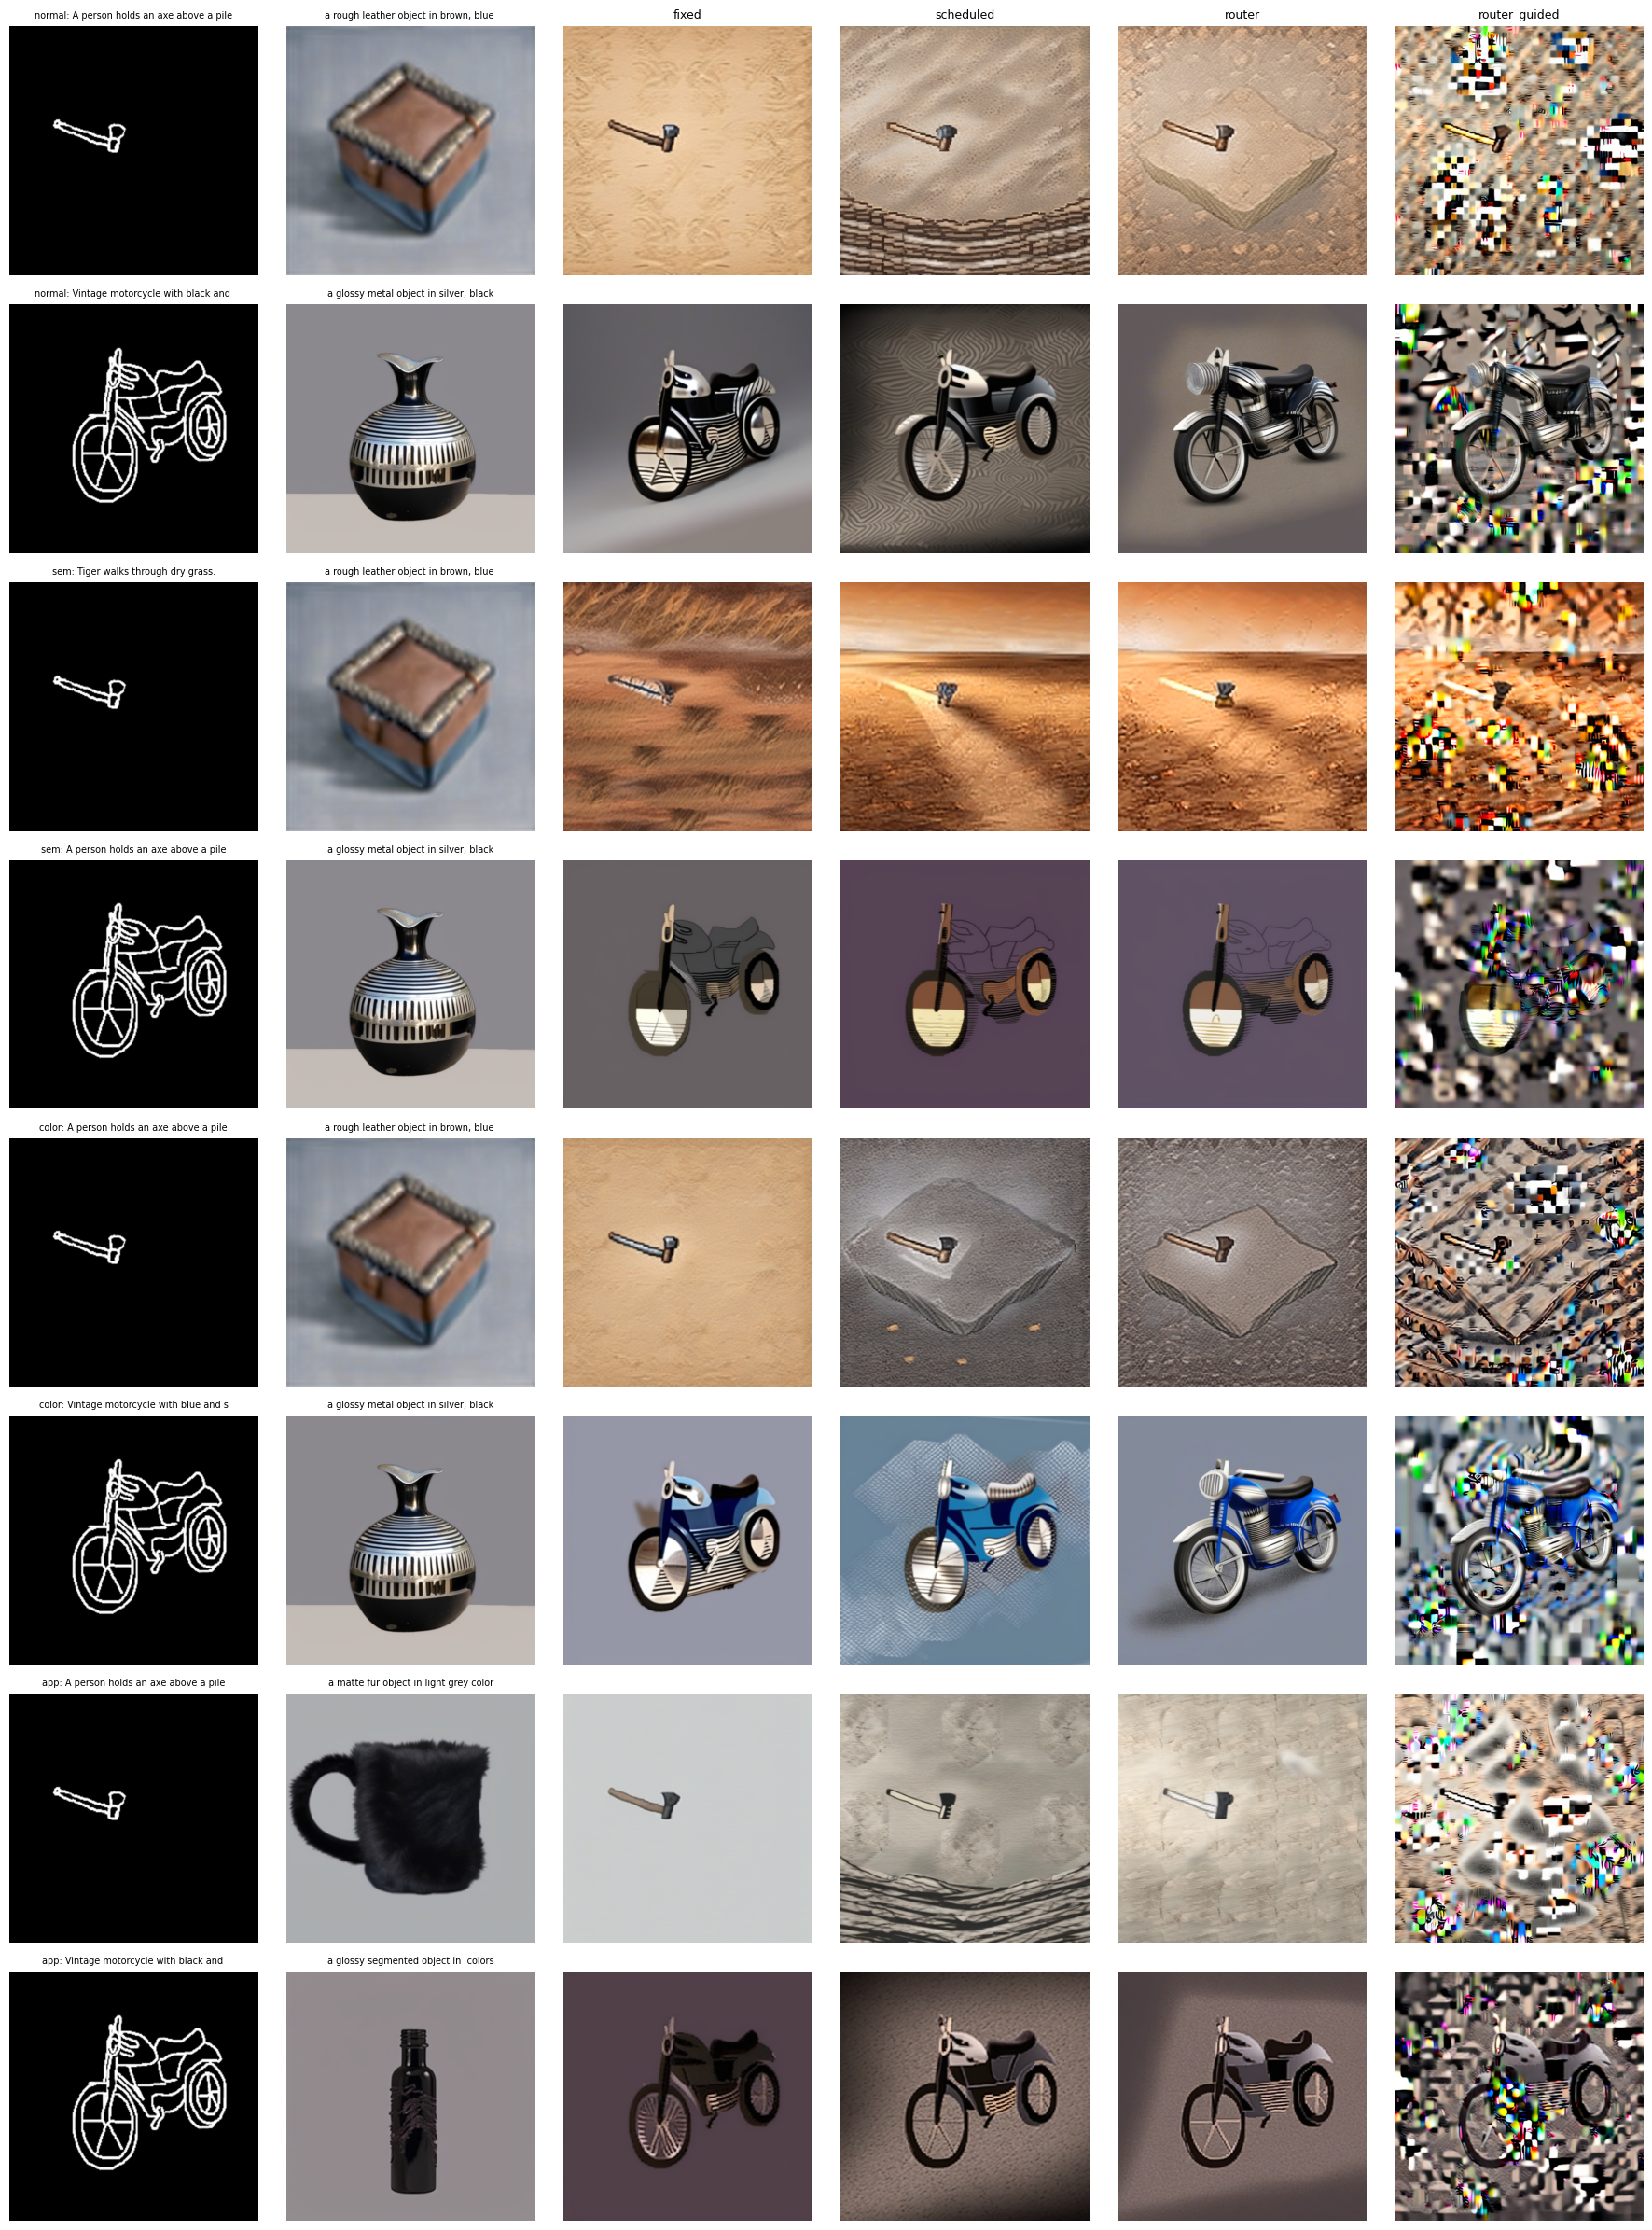

saved to /content/drive/MyDrive/sketchy_dataset_one_sketch/sdxl_runs/router_v2
files: scores.json, router.pt, manifest_eval.jsonl (feed to eval_metrics.py for FID/DreamSim), heldout.csv, results_per_item.csv, paired_comparisons.csv, contact_sheet.png


In [ ]:
# ---- qualitative contact sheet + files for the report ----
show = []
for g in ("normal", "object_conflict", "attribute_conflict", "ref_swap_conflict"):
    show += [i for i in eval_items if i["group"] == g][:2]
fig, ax = plt.subplots(len(show), 2 + len(ARMS), figsize=(3 * (2 + len(ARMS)), 3 * len(show)))
for r_, it in enumerate(show):
    ax[r_, 0].imshow(BASE[it["base"]]["sketch"]); ax[r_, 0].set_title(f"{it['kind']}: {it['caption'][:34]}", fontsize=7)
    ax[r_, 1].imshow(prep_ref(resolve(it["ref"]))); ax[r_, 1].set_title(it["attr"][:38], fontsize=7)
    for c, arm in enumerate(ARMS):
        ax[r_, 2 + c].imshow(Image.open(f"{OUT}/eval/{arm}/{it['key']}_s{EVAL_SEEDS[0]}.png"))
        if r_ == 0: ax[r_, 2 + c].set_title(arm, fontsize=9)
    for a in ax[r_]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/contact_sheet.png", dpi=110); plt.show()
print("saved to", OUT)
print("files: scores.json, router.pt, manifest_eval.jsonl (feed to eval_metrics.py for FID/DreamSim), heldout.csv, results_per_item.csv, paired_comparisons.csv, contact_sheet.png")

## Optional: interface (run only after everything above has finished)
Gradio app: upload a sketch and a reference, write a caption, and see all four arms with the router's chosen weights. Reloads the SDXL encoders onto the CPU (they are moved to the GPU only while encoding).

In [ ]:
!pip install -q gradio
import gradio as gr
te1 = CLIPTextModel.from_pretrained(BASE_ID, subfolder="text_encoder", torch_dtype=dt, variant="fp16")
te2 = CLIPTextModelWithProjection.from_pretrained(BASE_ID, subfolder="text_encoder_2", torch_dtype=dt, variant="fp16")
enc = CLIPVisionModelWithProjection.from_pretrained(IP_REPO, subfolder=ENC_SUBFOLDER, torch_dtype=dt)
for m in (te1, te2, enc): m.requires_grad_(False).eval()

def ui_encode(caption, ref_img):
    pipe.text_encoder, pipe.text_encoder_2, pipe.image_encoder = te1, te2, enc
    for m in (te1, te2, enc): m.to("cuda")
    try:
        txt, ipe = encode_text(caption), encode_ip(ref_img)
    finally:
        for m in (te1, te2, enc): m.to("cpu")
        pipe.text_encoder = pipe.text_encoder_2 = pipe.image_encoder = None
        gc.collect(); torch.cuda.empty_cache()
    return txt, ipe

UI_COLORS = ["red", "blue", "green", "yellow", "orange", "purple", "pink", "black", "white", "brown", "gray", "silver", "gold", "beige"]
UI_MATERIALS = ["wood", "metal", "plastic", "ceramic", "glass", "leather", "fabric", "stone"]
UI_FINISHES = ["glossy", "matte", "shiny metallic", "rough", "polished", "satin"]
@torch.no_grad()
def zero_shot(ref_emb, words, tmpl):
    return words[int((clip_txt([tmpl.format(w) for w in words]) @ ref_emb.T).argmax())]
def on_white(im):
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA"); im = Image.alpha_composite(Image.new("RGBA", im.size, (255, 255, 255, 255)), im)
    return im.convert("RGB")
def prep_sketch_pil(im):
    g = on_white(im).convert("L")
    if np.array(g).mean() > 127: g = ImageOps.invert(g)
    return letterbox(g.convert("RGB"), RES, (0, 0, 0))

@torch.no_grad()
def build_item(sketch_im, ref_im, caption, obj, attr_override, seed):
    sk = prep_sketch_pil(sketch_im); ref = letterbox(on_white(ref_im), RES, (127, 127, 127))
    sk_emb = clip_img(to_t(letterbox(ImageOps.invert(sk.convert("L")).convert("RGB"), 224, (255, 255, 255)))); ref_emb = clip_img(to_t(ref))
    attr = attr_override.strip() or f"a {zero_shot(ref_emb, UI_FINISHES, '{} surface')} {zero_shot(ref_emb, UI_MATERIALS, 'made of {}')} object in {zero_shot(ref_emb, UI_COLORS, '{} colored')} colors"
    BASE["ui"] = dict(sketch=sk, sk_emb=sk_emb, S_gh=soft_sketch(sk, GH), S_256=soft_sketch(sk, 256), thin256=thin_np(sk, 256), t_clip=None, t_dino=None)
    TXT[caption], IPC["ui"] = ui_encode(caption, ref)
    it = dict(key="ui", kind="ui", group="ui", base="ui", caption=caption, cap_category=(obj.strip() or caption), sk_category="", ref="ui", attr=attr, seed=int(seed))
    it["cap_emb"], it["attr_emb"] = clip_txt([caption]), clip_txt([attr]); it["obj_emb"] = clip_txt([f"a photo of a {it['cap_category']}"])
    it["feat"] = conflict_features(it, sk_emb, ref_emb)
    return it, sk

LABELS = {"fixed": "Fixed weights (baseline)", "scheduled": "Scheduled (geometry first)", "router": "Router (learned weights)", "router_guided": "Router + constraint guidance"}
def synthesize(sketch_im, ref_im, caption, obj, attr_override, choice, seed):
    if sketch_im is None or ref_im is None or not caption.strip(): raise gr.Error("Provide a sketch, a reference image and a caption.")
    it, sk = build_item(sketch_im, ref_im, caption.strip(), obj, attr_override, seed)
    arms = list(ARMS) if choice == "Compare all 4" else [k for k, v in LABELS.items() if v == choice]
    out, info = [], [f"reference attributes: {it['attr']}"]
    for arm in arms:
        p = params_for(it, arm)
        out.append((run_item(it, p, ARMS[arm]["shaped"], ARMS[arm]["guided"]), f"{LABELS[arm]} | sketch {p['cs']:.2f} hold {p['hold']:.2f} | ref {p['ip']:.2f} | text {p['cfg']:.1f}"))
        info.append(f"{LABELS[arm]}: sketch strength {p['cs']:.2f}, sketch hold {p['hold']:.2f}, reference strength {p['ip']:.2f}, text strength {p['cfg']:.1f}")
        torch.cuda.empty_cache()
    return out, sk, "\n".join(info)

with gr.Blocks(title="Attribute-routed multimodal diffusion") as demo:
    gr.Markdown("## Attribute-routed multimodal diffusion (SDXL)\nSketch -> geometry, caption -> semantics, reference -> appearance. The router sets how strongly each acts.")
    with gr.Row():
        with gr.Column():
            i_sk = gr.Image(type="pil", label="Sketch"); i_ref = gr.Image(type="pil", label="Reference image")
        with gr.Column():
            i_cap = gr.Textbox(label="Caption"); i_obj = gr.Textbox(label="Object name (optional)")
            i_attr = gr.Textbox(label="Reference attributes (optional; empty = predicted automatically)")
            i_arm = gr.Dropdown(["Compare all 4"] + list(LABELS.values()), value="Compare all 4", label="Method"); i_seed = gr.Number(value=0, precision=0, label="Seed")
            btn = gr.Button("Generate", variant="primary")
    o_gal = gr.Gallery(label="Results", columns=2, height=520)
    with gr.Row():
        o_sk = gr.Image(label="Sketch given to the model"); o_txt = gr.Textbox(label="What the router decided", lines=7)
    btn.click(synthesize, [i_sk, i_ref, i_cap, i_obj, i_attr, i_arm, i_seed], [o_gal, o_sk, o_txt])
demo.launch(share=True, debug=False)